In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from scipy.stats import chi2_contingency
from scipy.stats import ttest_ind
from scipy.stats import mannwhitneyu

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:

import pandas as pd

df = pd.read_csv('/content/cleaned_loan_dataset.csv')

print("Dataset loaded successfully!")

print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (614, 13)


,Customer_ID,Gender,Married,Dependents,Education,Self_Employed,Applicant_Income,Coapplicant_Income,Loan_Amount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,569,Female,No,0,Graduate,No,2378,0.0,9,360,1,Urban,N
1,15,Male,Yes,2,Graduate,No,1299,1086.0,17,120,1,Urban,Y
2,95,Male,No,0,Not Graduate,No,3620,0.0,25,120,1,Semiurban,Y
3,134,Male,Yes,0,Graduate,Yes,3459,0.0,25,120,1,Semiurban,Y
4,556,Male,Yes,1,Graduate,No,5468,1032.0,26,360,1,Semiurban,Y


In [3]:

print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include='all').T)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate records:", df.duplicated().sum())


Column names:
['Customer_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Applicant_Income', 'Coapplicant_Income', 'Loan_Amount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Customer_ID         614 non-null    int64  
 1   Gender              614 non-null    object 
 2   Married             614 non-null    object 
 3   Dependents          614 non-null    int64  
 4   Education           614 non-null    object 
 5   Self_Employed       614 non-null    object 
 6   Applicant_Income    614 non-null    int64  
 7   Coapplicant_Income  614 non-null    float64
 8   Loan_Amount         614 non-null    int64  
 9   Loan_Amount_Term    614 non-null    int64  
 10  Credit_History      614 non-null    int64  
 11  Property_

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Customer_ID,614.0,NaN,NaN,NaN,307.5,177.390811,1.0,154.25,307.5,460.75,614.0
Gender,614,2,Male,499,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Married,614,2,Yes,399,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,614.0,NaN,NaN,NaN,0.856678,1.216651,0.0,0.0,0.0,2.0,4.0
Education,614,2,Graduate,480,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Self_Employed,614,2,No,523,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Applicant_Income,614.0,NaN,NaN,NaN,5403.459283,6109.041673,150.0,2877.5,3812.5,5795.0,81000.0
Coapplicant_Income,614.0,NaN,NaN,NaN,1621.245798,2926.248369,0.0,0.0,1188.5,2297.25,41667.0
Loan_Amount,614.0,NaN,NaN,NaN,142.022801,87.083089,9.0,98.0,125.0,164.75,700.0
Loan_Amount_Term,614.0,NaN,NaN,NaN,338.892508,69.716355,12.0,360.0,360.0,360.0,480.0



Missing values:
Customer_ID           0
Gender                0
Married               0
Dependents            0
Education             0
Self_Employed         0
Applicant_Income      0
Coapplicant_Income    0
Loan_Amount           0
Loan_Amount_Term      0
Credit_History        0
Property_Area         0
Loan_Status           0
dtype: int64

Duplicate records: 0


In [4]:

print(df['Loan_Status'].value_counts())

print("\nApproval percentages:")
print(df['Loan_Status'].value_counts(normalize=True) * 100)


Loan_Status
Y    422
N    192
Name: count, dtype: int64

Approval percentages:
Loan_Status
Y    68.729642
N    31.270358
Name: proportion, dtype: float64


In [5]:
print("Dataset columns:")
print(df.columns.tolist())

Dataset columns:
['Customer_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Applicant_Income', 'Coapplicant_Income', 'Loan_Amount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status']


In [6]:
print(df['Loan_Status'].value_counts())

Loan_Status
Y    422
N    192
Name: count, dtype: int64


Form Statistical Research Question

The following questions are selected to understand the relationship between applicant details and loan approval status.

1. Is credit history significantly associated with loan approval?
2. Is education significantly associated with loan approval?
3. Is there a significant difference in applicant income between approved and rejected loans?
4. Is there a significant difference in loan amount between approved and rejected loans?

**Significance level (α): 0.05**

**Statistical methods:**
- Chi-square test for categorical variables.
- Welch's independent t-test for numerical variables, subject to checking assumptions.




In [7]:
# Check missing values
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
Customer_ID           0
Gender                0
Married               0
Dependents            0
Education             0
Self_Employed         0
Applicant_Income      0
Coapplicant_Income    0
Loan_Amount           0
Loan_Amount_Term      0
Credit_History        0
Property_Area         0
Loan_Status           0
dtype: int64


In [8]:
# Check duplicate records
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [9]:
# Check basic statistical information
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Customer_ID,614.0,307.500000,177.390811,1.0,154.25,307.5,460.75,614.0
Dependents,614.0,0.856678,1.216651,0.0,0.00,0.0,2.00,4.0
Applicant_Income,614.0,5403.459283,6109.041673,150.0,2877.50,3812.5,5795.00,81000.0
Coapplicant_Income,614.0,1621.245798,2926.248369,0.0,0.00,1188.5,2297.25,41667.0
Loan_Amount,614.0,142.022801,87.083089,9.0,98.00,125.0,164.75,700.0
Loan_Amount_Term,614.0,338.892508,69.716355,12.0,360.00,360.0,360.00,480.0
Credit_History,614.0,0.850163,0.357203,0.0,1.00,1.0,1.00,1.0


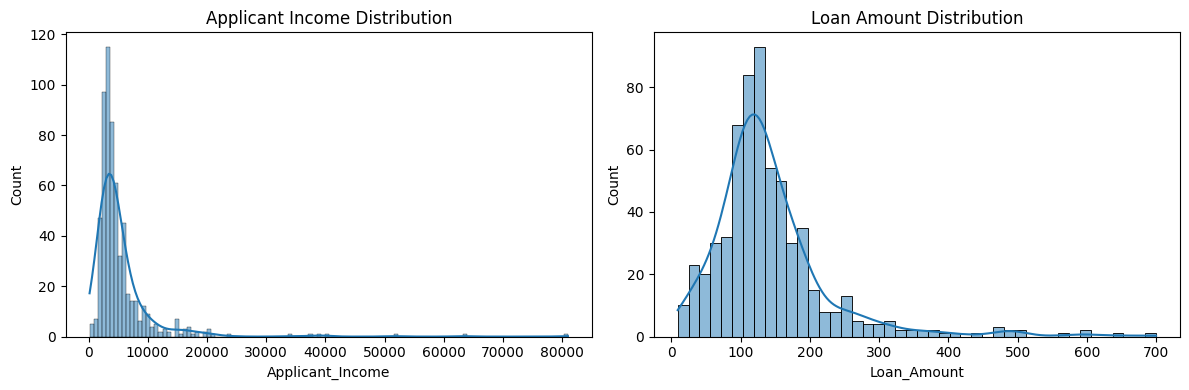

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
sns.histplot(df['Applicant_Income'], kde=True)
plt.title('Applicant Income Distribution')

plt.subplot(1, 2, 2)
sns.histplot(df['Loan_Amount'], kde=True)
plt.title('Loan Amount Distribution')

plt.tight_layout()
plt.show()

In [11]:
# Check skewness of numerical columns

print("Applicant Income Skewness:",
      df['Applicant_Income'].skew())

print("Loan Amount Skewness:",
      df['Loan_Amount'].skew())

Applicant Income Skewness: 6.539513113994623
Loan Amount Skewness: 2.500953472109778


Distribution Analysis
- Applicant Income has a skewness of 6.54, indicating a highly right-skewed distribution.
- Loan Amount has a skewness of 2.50, indicating a highly right-skewed distribution.
- Both variables are not normally distributed based on their skewness.
- Therefore, we will consider the Mann–Whitney U test for comparing these variables between approved and rejected loan groups.

Checking whether Credit History is associated with Loan Approval.

In [12]:
from scipy.stats import chi2_contingency

# Create a contingency table
table = pd.crosstab(df['Credit_History'], df['Loan_Status'])

print("Contingency Table:")
print(table)

# Perform Chi-square test
chi2, p_value, dof, expected = chi2_contingency(table)

print("\nChi-square value:", chi2)
print("P-value:", p_value)
print("Degrees of freedom:", dof)

print("\nExpected Frequencies:")
print(expected)

Contingency Table:
Loan_Status       N    Y
Credit_History          
0                82   10
1               110  412

Chi-square value: 165.41297462928864
P-value: 7.43185533269261e-38
Degrees of freedom: 1

Expected Frequencies:
[[ 28.76872964  63.23127036]
 [163.23127036 358.76872964]]


STATISTICAL TEST-01(Credit History vs Loan Status)

Result and Interpretation – Credit History
- Statistical test used: Chi-square test of independence.
- Chi-square value: 165.413.
- P-value: 7.43 × 10⁻³⁸.
- Significance level: 0.05.
- Since the p-value is less than 0.05, the null hypothesis is rejected.
- There is a significant association between credit history and loan approval status.
- Applicants with Credit_History = 1 had a much higher approval rate than applicants with Credit_History = 0.

Business insight: Credit history is an important factor associated with loan approval. Applicants with a positive credit history were more likely to receive loan approval in this dataset.

Investigating our second question:

Is education significantly associated with loan approval?

In [13]:
from scipy.stats import chi2_contingency

# Create a contingency table
table_education = pd.crosstab(
    df['Education'],
    df['Loan_Status']
)

print("Education vs Loan Status:")
print(table_education)

# Perform Chi-square test
chi2, p_value, dof, expected = chi2_contingency(
    table_education
)

print("\nChi-square value:", chi2)
print("P-value:", p_value)
print("Degrees of freedom:", dof)

print("\nExpected Frequencies:")
print(expected)

Education vs Loan Status:
Loan_Status     N    Y
Education             
Graduate      140  340
Not Graduate   52   82

Chi-square value: 4.091490413303621
P-value: 0.04309962129357355
Degrees of freedom: 1

Expected Frequencies:
[[150.09771987 329.90228013]
 [ 41.90228013  92.09771987]]


Statistical Test 2: Education vs Loan Status
Result and Interpretation – Education
- Statistical test used: Chi-square test of independence.
- Chi-square value: 4.0915.
- P-value: 0.0431.
- Significance level: 0.05.
- Since the p-value is less than 0.05, the null hypothesis is rejected.
- There is a statistically significant association between education and loan approval status.
- The evidence is relatively weak because the p-value is close to the significance level.
Business insight: Education level shows a statistically significant association with loan approval in this dataset. However, education alone should not be considered sufficient to determine loan approval.

Is applicant income significantly different between approved and rejected loans?

In [14]:
from scipy.stats import mannwhitneyu

# Separate income based on loan status
approved_income = df[df['Loan_Status'] == 'Y']['Applicant_Income']

rejected_income = df[df['Loan_Status'] == 'N']['Applicant_Income']

# Perform Mann-Whitney U test
statistic, p_value = mannwhitneyu(
    approved_income,
    rejected_income,
    alternative='two-sided'
)

print("Mann-Whitney U Statistic:", statistic)
print("P-value:", p_value)

print("\nMedian Applicant Income:")
print("Approved:", approved_income.median())
print("Rejected:", rejected_income.median())

Mann-Whitney U Statistic: 40302.0
P-value: 0.91811428057985

Median Applicant Income:
Approved: 3812.5
Rejected: 3833.5


Statistical Test 3: Applicant Income vs Loan Status
Result and Interpretation – Applicant Income
- Statistical test used: Mann–Whitney U test.
- U statistic: 40302.0.
- P-value: 0.9181.
- Significance level: 0.05.
- Since the p-value is greater than 0.05, we fail to reject the null hypothesis.
- There is insufficient evidence of a significant difference in applicant income distributions between approved and rejected loans.
- Median income of approved applicants: 3812.5.
- Median income of rejected applicants: 3833.5.
Business insight: Applicant income alone did not show a statistically significant difference between approved and rejected loan groups in this dataset.

Is loan amount significantly different between approved and rejected loans?

In [15]:
from scipy.stats import mannwhitneyu

# Separate loan amounts based on loan status
approved_loan = df[df['Loan_Status'] == 'Y']['Loan_Amount']

rejected_loan = df[df['Loan_Status'] == 'N']['Loan_Amount']

# Perform Mann-Whitney U test
statistic, p_value = mannwhitneyu(
    approved_loan,
    rejected_loan,
    alternative='two-sided'
)

print("Mann-Whitney U Statistic:", statistic)
print("P-value:", p_value)

print("\nMedian Loan Amount:")
print("Approved:", approved_loan.median())
print("Rejected:", rejected_loan.median())

Mann-Whitney U Statistic: 40139.0
P-value: 0.8549455380593638

Median Loan Amount:
Approved: 125.0
Rejected: 126.5


Statistical Test 4: Loan Amount vs Loan Status
Results and Interpretation:
- P-value (0.8549) is greater than 0.05.
- Therefore, we fail to reject H₀.
- There is no statistically significant evidence of a difference in loan amount distributions between approved and rejected groups.
- The median loan amounts are also very similar.

### Overall Conclusion

Four statistical tests were performed to identify relationships between applicant details and loan approval status.

- Credit History showed a highly significant association with loan approval.
- Education showed a statistically significant but relatively weak association with loan approval.
- Applicant Income did not show a statistically significant difference between approved and rejected groups.
- Loan Amount also did not show a statistically significant difference between approved and rejected groups.

Among the four factors tested, Credit History showed the strongest statistical association with Loan Status.

These findings describe associations in the available dataset. They do not prove that any factor directly causes loan approval or rejection.